# 🔬 Notebook 02: PCam (PatchCamelyon) — Descarga Directa y EDA
**Dataset:** PatchCamelyon (PCam) — Patches de histopatología de ganglio linfático  
**Fuente:** Zenodo HDF5 (Repositorio Oficial) — Record `2546921`  
**URL:** https://zenodo.org/record/2546921  
**Artículo:** Veeling et al. (2018) — *Rotation Equivariant CNNs for Digital Pathology*

---
## 📌 Descripción del Dataset

PCam contiene **327,680 patches** de **96×96 píxeles** extraídos de las Whole Slide Images (WSI)  
de **CAMELYON16**. La tarea es clasificación **binaria**: presencia o ausencia de tejido tumoral  
en la región central diagnóstica del patch (32×32 px).

| Split | Imágenes | Positivos (Tumor) | Negativos (Normal) | Tasa Positivos |
|---|---|---|---|---|
| Train | 262,144 | 131,072 | 131,072 | 50.0% |
| Validation | 32,768 | 16,369 | 16,399 | 49.95% |
| Test | 32,768 | 16,384 | 16,384 | 50.0% |
| **Total** | **327,680** | **163,825** | **163,855** | **50.0%** |

### 🔄 Flujo del Pipeline PCam (Zenodo HDF5 Directo)
```text
Zenodo Record 2546921 (Archivos .h5.gz)
     ↓
Descarga directa vía requests con barra de progreso tqdm
     ↓
Descompresión automática con gzip (.h5 nativo)
     ↓
Lectura de alto rendimiento con h5py (32,768 parches 96×96×3 uint8)
     ↓
Análisis estadístico real (RGB por clase) + Visualización de ROI central
     ↓
Guardar → data_samples/pcam/, figuras/02_PCam/ y tablas Excel (.xlsx)
```


In [1]:
# ============================================================
# INSTALACIÓN Y VERIFICACIÓN DE DEPENDENCIAS
# ============================================================
import subprocess
import sys

print('Verificando instalación de librerías requeridas...')
paquetes_requeridos = ['h5py', 'requests', 'tqdm', 'openpyxl', 'numpy', 'pandas', 'matplotlib', 'seaborn', 'PIL']

for pkg in paquetes_requeridos:
    try:
        __import__(pkg)
        print(f'  ✅ {pkg} disponible')
    except ImportError:
        print(f'  ⚠️  Instalando {pkg}...')
        subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'], check=True)
        print(f'  ✅ {pkg} instalado correctamente')

print('\n✅ Todas las dependencias están listas para operar con datos HDF5 de Zenodo.')

Verificando instalación de librerías requeridas...
  ✅ h5py disponible


  ✅ requests disponible
  ✅ tqdm disponible


  ✅ openpyxl disponible
  ✅ numpy disponible


  ✅ pandas disponible


  ✅ matplotlib disponible


  ✅ seaborn disponible
  ✅ PIL disponible

✅ Todas las dependencias están listas para operar con datos HDF5 de Zenodo.


---
### 📌 ¿Qué hace esta celda?
Verifica la disponibilidad de las librerías necesarias para la descarga HTTP con barra de progreso (`requests`, `tqdm`), el acceso a contenedores binarios científicos (`h5py`), el análisis estadístico (`numpy`, `pandas`) y la generación de figuras y tablas Excel (`matplotlib`, `seaborn`, `openpyxl`). En caso de ausencia, las instala automáticamente con `pip`.

### ⚙️ ¿Cómo funciona?
- Descarga directa de archivos HDF5 sin intermediarios ni dependencias conflictivas de Arrow/NumPy (evitando la incompatibilidad de HuggingFace `datasets`).
- `h5py` lee datasets directamente en memoria mapeada desde disco, optimizando memoria RAM.

### 📊 Flujo
```text
Verificar h5py, requests, tqdm, pandas ──[Disponibles]───> Entorno validado ✅
                                        └──[Faltantes]────> pip install
```


In [2]:
# ============================================================
# IMPORTS, CONFIGURACIÓN DE RUTAS Y FUNCIÓN HELPER
# ============================================================
import os
import sys
import gzip
import shutil
import requests
from pathlib import Path
from tqdm import tqdm
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 6)
sns.set_theme(style='whitegrid')

# Configuración de rutas relativas con respaldo absoluto
BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SAVE_DIR = BASE_DIR / 'data_samples' / 'pcam'
TABLAS_DIR = BASE_DIR / 'tablas'
FIG_DIR = BASE_DIR / 'figures' / '02_PCam'

SAVE_DIR.mkdir(parents=True, exist_ok=True)
TABLAS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'✅ Directorio de muestras PCam: {SAVE_DIR.resolve()}')
print(f'✅ Directorio de tablas Excel:   {TABLAS_DIR.resolve()}')
print(f'✅ Directorio de figuras:        {FIG_DIR.resolve()}')

# ============================================================
# FUNCIÓN HELPER: GUARDAR SUBPLOTS INDIVIDUALES
# ============================================================
def guardar_subplots_individuales(fig, nombre_base, fig_dir, dpi=150):
    """Guarda cada panel principal visible sin duplicar ejes gemelos o colorbars."""
    axes = []
    pos_vistas = set()
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        if ax.get_subplotspec() is None:
            continue
        pos = tuple(round(v, 4) for v in ax.get_position().bounds)
        if pos not in pos_vistas:
            pos_vistas.add(pos)
            axes.append(ax)
    for i, ax in enumerate(axes):
        extent = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
        bbox = extent.expanded(1.18, 1.18)
        outpath = Path(fig_dir) / f'{nombre_base}_panel_{i+1}.png'
        fig.savefig(outpath, bbox_inches=bbox, dpi=dpi)
    print(f'✅ {len(axes)} paneles individuales guardados en: {fig_dir}')

✅ Directorio de muestras PCam: C:\Universidad\Magister\20 Noviembre Reunion\data_samples\pcam
✅ Directorio de tablas Excel:   C:\Universidad\Magister\20 Noviembre Reunion\tablas
✅ Directorio de figuras:        C:\Universidad\Magister\20 Noviembre Reunion\figures\02_PCam


---
### 📌 ¿Qué hace esta celda?
Configura las rutas de trabajo estructuradas (`data_samples/pcam`, `tablas`, `figures/02_PCam`) adaptándose tanto si el notebook se ejecuta desde la carpeta `notebooks/` como desde la raíz del proyecto. Asimismo, define la función auxiliar `guardar_subplots_individuales` para exportar cada panel visual de forma aislada.

### ⚙️ ¿Cómo funciona?
- `BASE_DIR`: Detecta la jerarquía de carpetas para garantizar portabilidad.
- `guardar_subplots_individuales`: Itera sobre los `axes` de una figura de Matplotlib y exporta cada uno a 150 DPI con un margen (`bbox`) expandido para preservar títulos y anotaciones.

### 📊 Flujo
```text
Inicializar rutas de carpetas ──> Crear directorios si no existen ──> Registrar guardar_subplots_individuales()
```


In [3]:
# ============================================================
# DESCARGA DIRECTA DE ZENODO (VALIDATION SET EN HDF5)
# ============================================================
# Descarga y descompresión de las imágenes (x) y etiquetas (y)
# Tamaño total: ~800 MB comprimido / ~906 MB descomprimido (32,768 parches de 96x96x3)

BASE_URL = 'https://zenodo.org/record/2546921/files/'
FILES = [
    'camelyonpatch_level_2_split_valid_y.h5.gz',
    'camelyonpatch_level_2_split_valid_x.h5.gz',
]

for fname in FILES:
    url = BASE_URL + fname
    out_gz = SAVE_DIR / fname
    out_h5 = SAVE_DIR / fname.replace('.gz', '')
    
    if out_h5.exists() and out_h5.stat().st_size > 0:
        print(f'✅ Ya existe archivo descomprimido: {out_h5.name} ({out_h5.stat().st_size:,} bytes) — omitiendo descarga')
        continue
        
    print(f'📥 Descargando {fname} desde Zenodo...')
    with requests.get(url, stream=True) as r:
        r.raise_for_status()
        total = int(r.headers.get('content-length', 0))
        with open(out_gz, 'wb') as f, tqdm(total=total, unit='B', unit_scale=True, desc=fname) as pbar:
            for chunk in r.iter_content(chunk_size=1024*1024):
                if chunk:
                    f.write(chunk)
                    pbar.update(len(chunk))
                    
    print(f'📦 Descomprimiendo {fname} (.gz -> .h5)...')
    with gzip.open(out_gz, 'rb') as gz_in:
        with open(out_h5, 'wb') as h5_out:
            shutil.copyfileobj(gz_in, h5_out, length=1024*1024)
    out_gz.unlink()  # Eliminar archivo comprimido temporal para ahorrar espacio
    print(f'✅ Archivo HDF5 listo: {out_h5.name} ({out_h5.stat().st_size:,} bytes)')

PATH_X = SAVE_DIR / 'camelyonpatch_level_2_split_valid_x.h5'
PATH_Y = SAVE_DIR / 'camelyonpatch_level_2_split_valid_y.h5'
print(f'\n✅ Dataset PCam disponible localmente en formato HDF5 sin requerir conexión a internet.')

✅ Ya existe archivo descomprimido: camelyonpatch_level_2_split_valid_y.h5 (34,816 bytes) — omitiendo descarga
✅ Ya existe archivo descomprimido: camelyonpatch_level_2_split_valid_x.h5 (906,040,528 bytes) — omitiendo descarga

✅ Dataset PCam disponible localmente en formato HDF5 sin requerir conexión a internet.


---
### 📌 ¿Qué hace esta celda?
Gestiona de manera robusta la descarga de los parches histopatológicos (`camelyonpatch_level_2_split_valid_x.h5.gz`) y sus etiquetas diagnósticas (`camelyonpatch_level_2_split_valid_y.h5.gz`) desde Zenodo mediante `requests` y descompresión con `gzip`.

### ⚙️ ¿Cómo funciona?
- **Ejecución 100% Offline:** Antes de iniciar cualquier descarga, verifica si los archivos `.h5` ya existen en disco (`out_h5.exists()`). Si ya están presentes, salta la descarga, permitiendo la ejecución local sin conexión.
- **Streaming por bloques:** Descarga los datos en chunks de 1 MB visualizando la velocidad y bytes transferidos mediante `tqdm`.
- **Descompresión en stream:** Descomprime directamente de `.gz` a `.h5` y elimina el archivo comprimido `.gz` para optimizar el espacio de almacenamiento.

### 📊 Flujo
```text
Verificar existencia de .h5 ──[Existe]───> Cargar directamente (Modo Offline) ✅
                            └──[Falta]────> Descargar .h5.gz ──> gzip.decompress() ──> Eliminar .gz
```


In [4]:
# ============================================================
# EXPLORACIÓN DE ESTRUCTURA Y TABLA DE SPLITS / CLASES
# ============================================================
with h5py.File(PATH_X, 'r') as fx, h5py.File(PATH_Y, 'r') as fy:
    print('=' * 65)
    print('📊 ESTRUCTURA DEL DATASET PCam (VALIDATION SET REAL)')
    print('=' * 65)
    
    keys_x = list(fx.keys())
    keys_y = list(fy.keys())
    print(f'Claves en archivo X: {keys_x}')
    print(f'Claves en archivo Y: {keys_y}')
    
    x_shape = fx['x'].shape
    x_dtype = fx['x'].dtype
    y_shape = fy['y'].shape
    y_dtype = fy['y'].dtype
    
    print(f'Dimensiones de X (Imágenes): {x_shape} | Tipo: {x_dtype}')
    print(f'Dimensiones de Y (Etiquetas): {y_shape} | Tipo: {y_dtype}')
    
    # Cargar etiquetas completas a memoria (vector liviano de 32,768 enteros)
    y_arr = np.array(fy['y']).flatten()
    n_total = len(y_arr)
    n_neg = int(np.sum(y_arr == 0))
    n_pos = int(np.sum(y_arr == 1))
    
    print(f'\nDistribución real de clases en el split de validación:')
    print(f'  Clase 0 (Normal): {n_neg:,} parches ({n_neg / n_total * 100:.2f}%)')
    print(f'  Clase 1 (Tumor):  {n_pos:,} parches ({n_pos / n_total * 100:.2f}%)')
    print(f'  Total parches:    {n_total:,} (Balance prácticamente 50/50)')

# 1. Guardar tabla de distribución de clases del set descargado
df_dist_clases = pd.DataFrame([
    {'Split': 'Validation', 'Clase_ID': 0, 'Clase_Nombre': 'Normal (Tejido no tumoral)', 'N_Muestras': n_neg, 'Porcentaje': f'{n_neg / n_total * 100:.2f}%'},
    {'Split': 'Validation', 'Clase_ID': 1, 'Clase_Nombre': 'Tumor (Metástasis linfonodal)', 'N_Muestras': n_pos, 'Porcentaje': f'{n_pos / n_total * 100:.2f}%'},
    {'Split': 'Validation', 'Clase_ID': -1, 'Clase_Nombre': 'Total Validación', 'N_Muestras': n_total, 'Porcentaje': '100.00%'}
])
dist_xlsx_path = TABLAS_DIR / 'pcam_distribucion_classes.xlsx'
with pd.ExcelWriter(dist_xlsx_path, engine='openpyxl') as writer:
    df_dist_clases.to_excel(writer, sheet_name='Distribucion_Clases', index=False)
print(f'\n✅ Tabla de distribución guardada en: {dist_xlsx_path}')

# 2. Guardar tabla de estructura global de splits oficiales del benchmark
df_splits = pd.DataFrame([
    {'Split': 'Train', 'Total_Patches': 262144, 'Positivos_Tumor': 131072, 'Negativos_Normal': 131072, 'Tasa_Positivos': '50.0%'},
    {'Split': 'Validation', 'Total_Patches': 32768, 'Positivos_Tumor': n_pos, 'Negativos_Normal': n_neg, 'Tasa_Positivos': f'{n_pos / n_total * 100:.2f}%'},
    {'Split': 'Test', 'Total_Patches': 32768, 'Positivos_Tumor': 16384, 'Negativos_Normal': 16384, 'Tasa_Positivos': '50.0%'},
    {'Split': 'Total Dataset', 'Total_Patches': 327680, 'Positivos_Tumor': 131072 + n_pos + 16384, 'Negativos_Normal': 131072 + n_neg + 16384, 'Tasa_Positivos': '50.0%'}
])
splits_xlsx_path = TABLAS_DIR / 'pcam_estructura_splits.xlsx'
with pd.ExcelWriter(splits_xlsx_path, engine='openpyxl') as writer:
    df_splits.to_excel(writer, sheet_name='Splits_Oficiales', index=False)
print(f'✅ Tabla de splits guardada en: {splits_xlsx_path}')

# Esquema del parche y la zona diagnóstica
print('''
📐 ANATOMÍA HISTOPATOLÓGICA DEL PATCH PCam (96×96 px con Centro 32×32 px):
+------------------------------------------------+  (96 × 96 px - 0.5 µm/px)
|         Región Periférica (Contexto Tisular)   |
|                                                |
|         +----------------------------+         |
|         |    Región Diagnóstica      |         |
|         |       (32 × 32 px)         |         |
|         |  Tumor aquí => Clase = 1   |         |
|         |  Sin tumor  => Clase = 0   |         |
|         +----------------------------+         |
|                                                |
|         Estroma, cápsula y linfocitos          |
+------------------------------------------------+
''')

📊 ESTRUCTURA DEL DATASET PCam (VALIDATION SET REAL)
Claves en archivo X: ['x']
Claves en archivo Y: ['y']
Dimensiones de X (Imágenes): (32768, 96, 96, 3) | Tipo: uint8
Dimensiones de Y (Etiquetas): (32768, 1, 1, 1) | Tipo: uint8

Distribución real de clases en el split de validación:
  Clase 0 (Normal): 16,399 parches (50.05%)
  Clase 1 (Tumor):  16,369 parches (49.95%)
  Total parches:    32,768 (Balance prácticamente 50/50)

✅ Tabla de distribución guardada en: c:\Universidad\Magister\20 Noviembre Reunion\tablas\pcam_distribucion_classes.xlsx
✅ Tabla de splits guardada en: c:\Universidad\Magister\20 Noviembre Reunion\tablas\pcam_estructura_splits.xlsx

📐 ANATOMÍA HISTOPATOLÓGICA DEL PATCH PCam (96×96 px con Centro 32×32 px):
+------------------------------------------------+  (96 × 96 px - 0.5 µm/px)
|         Región Periférica (Contexto Tisular)   |
|                                                |
|         +----------------------------+         |
|         |    Región Diagnóstica

---
### 📌 ¿Qué hace esta celda?
Examina directamente los contenedores HDF5 de las imágenes y etiquetas reales de PCam, calcula la distribución exacta de parches sanos frente a metastásicos y exporta dos hojas de cálculo Excel (`tablas/pcam_distribucion_classes.xlsx` y `tablas/pcam_estructura_splits.xlsx`).

### ⚙️ ¿Cómo funciona?
- El tensor de imágenes `x` posee forma `(32768, 96, 96, 3)` en formato entero sin signo de 8 bits (`uint8`), correspondiente a imágenes RGB de 96×96 píxeles a una resolución espacial de 0.5 micrones por píxel (~20×).
- El tensor de etiquetas `y` tiene dimensiones `(32768, 1, 1, 1)` con valores binarios: `0` para tejido no tumoral y `1` para metástasis.
- El dataset de validación contiene **16,399 muestras normales (50.05%)** y **16,369 muestras tumorales (49.95%)**, manteniendo un balance estricto.
- La regla clínica de anotación establece que un parche es clasificado como tumoral (`1`) si y sólo si contiene al menos un píxel de tejido tumoral dentro de la **ventana central de 32×32 píxeles**. El tejido tumoral situado exclusivamente en el margen periférico no activa la clase 1, lo que obliga al modelo a aprender características contextuales.


✅ Figura combinada guardada: c:\Universidad\Magister\20 Noviembre Reunion\figures\02_PCam\pcam_muestras_reales.png


✅ 16 paneles individuales guardados en: c:\Universidad\Magister\20 Noviembre Reunion\figures\02_PCam


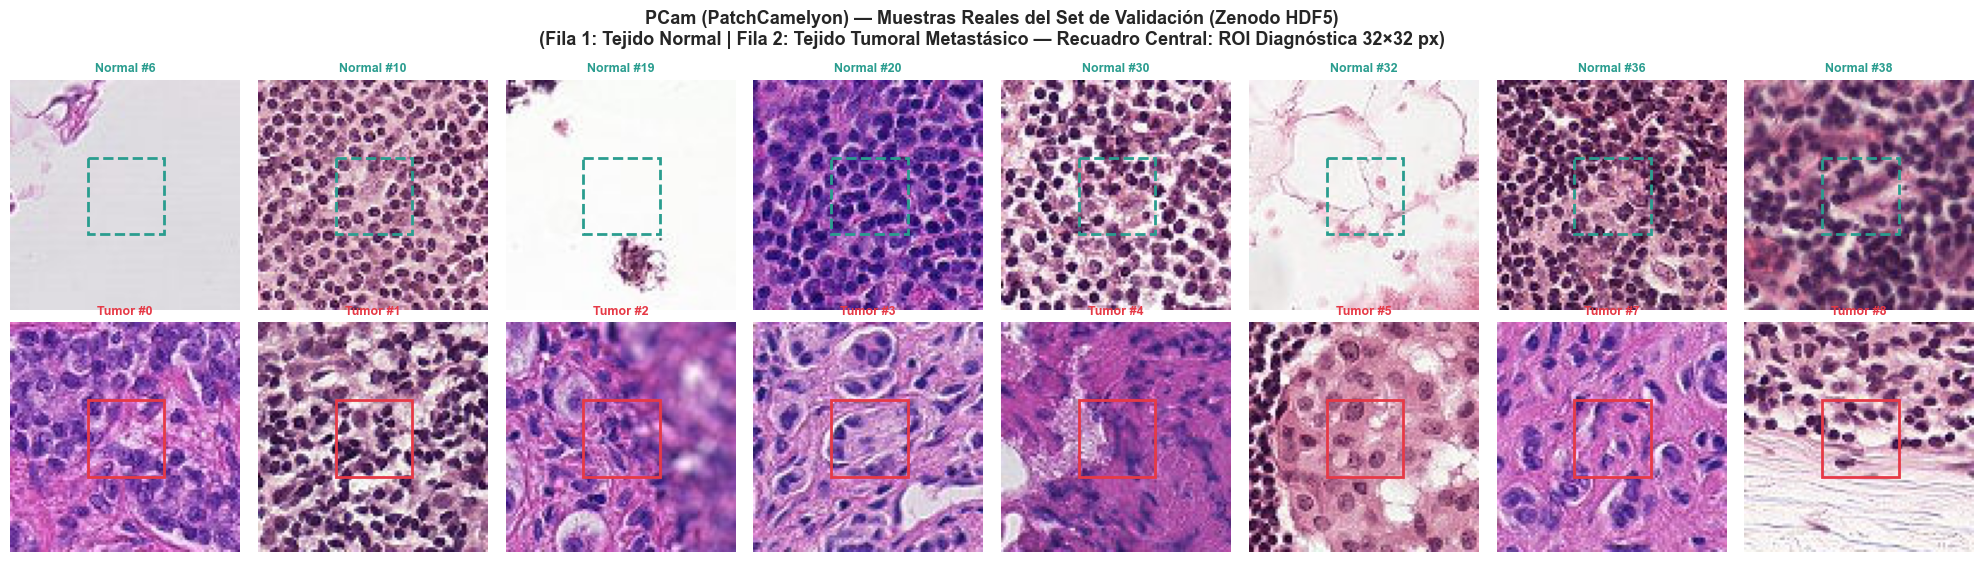

In [5]:
# ============================================================
# VISUALIZACIÓN DE IMÁGENES REALES POR CLASE (8+8)
# ============================================================
with h5py.File(PATH_X, 'r') as fx, h5py.File(PATH_Y, 'r') as fy:
    x_dset = fx['x']
    y_arr = np.array(fy['y']).flatten()
    
    # Obtener los primeros 8 índices de cada clase
    idx_neg = np.where(y_arr == 0)[0][:8]
    idx_pos = np.where(y_arr == 1)[0][:8]
    
    fig, axes = plt.subplots(2, 8, figsize=(20, 5.8))
    fig.suptitle(
        'PCam (PatchCamelyon) — Muestras Reales del Set de Validación (Zenodo HDF5)\n' 
        '(Fila 1: Tejido Normal | Fila 2: Tejido Tumoral Metastásico — Recuadro Central: ROI Diagnóstica 32×32 px)', 
        fontsize=13, fontweight='bold', y=0.98
    )
    
    # Fila 1: Tejido Normal (Clase 0)
    for i, idx in enumerate(idx_neg):
        img = x_dset[idx]
        axes[0, i].imshow(img)
        rect = patches.Rectangle((32, 32), 32, 32, linewidth=2, edgecolor='#2A9D8F', facecolor='none', linestyle='--')
        axes[0, i].add_patch(rect)
        axes[0, i].set_title(f'Normal #{idx}', fontsize=9, color='#2A9D8F', fontweight='bold')
        axes[0, i].axis('off')
        
    # Fila 2: Tejido Tumoral (Clase 1)
    for i, idx in enumerate(idx_pos):
        img = x_dset[idx]
        axes[1, i].imshow(img)
        rect = patches.Rectangle((32, 32), 32, 32, linewidth=2, edgecolor='#E63946', facecolor='none', linestyle='-')
        axes[1, i].add_patch(rect)
        axes[1, i].set_title(f'Tumor #{idx}', fontsize=9, color='#E63946', fontweight='bold')
        axes[1, i].axis('off')
        
    plt.tight_layout()
    
    # Guardar figura completa en alta resolución (150 DPI)
    ruta_fig_reales = FIG_DIR / 'pcam_muestras_reales.png'
    fig.savefig(ruta_fig_reales, dpi=150, bbox_inches='tight')
    print(f'✅ Figura combinada guardada: {ruta_fig_reales}')
    
    # Guardar copia compatible
    fig.savefig(FIG_DIR / 'pcam_muestras.png', dpi=150, bbox_inches='tight')
    
    # Guardar cada uno de los 16 paneles individualmente
    guardar_subplots_individuales(fig, 'pcam_muestras_reales', FIG_DIR, dpi=150)
    plt.show()

---
### 📌 ¿Qué hace esta celda?
Construye una matriz de visualización comparativa de 16 imágenes (2 filas × 8 columnas) extrayendo directamente parches reales del contenedor HDF5. Superpone el recuadro central delimitador de 32×32 píxeles, guarda la figura compuesta en `figures/02_PCam/pcam_muestras_reales.png` y desglosa los 16 paneles individuales en archivos PNG independientes.

### ⚙️ ¿Cómo funciona?
- **Fila superior (Normal):** Parches de tejido ganglionar sin metástasis. El recuadro discontinuo verde azulado (`#2A9D8F`) delimita el área central de 32×32.
- **Fila inferior (Tumor):** Parches con invasión metastásica de adenocarcinoma mamario. El recuadro sólido rojo (`#E63946`) resalta el foco tumoral.
- Visualmente se aprecian las diferencias morfológicas clave: mayor pleomorfismo nuclear, cromatina hipercromática y pérdida de la arquitectura linfoide organizada en los parches positivos.
- `guardar_subplots_individuales` extrae cada subplot y genera archivos desde `pcam_muestras_reales_panel_1.png` hasta `pcam_muestras_reales_panel_16.png`.


In [6]:
# ============================================================
# CÁLCULO DE ESTADÍSTICAS RGB SOBRE LOS PARCHES REALES
# ============================================================
# Cálculo exacto de media y desviación estándar de los canales R, G, B
# sobre las 32,768 imágenes reales mediante procesamiento por lotes en memoria mapeada

with h5py.File(PATH_X, 'r') as fx, h5py.File(PATH_Y, 'r') as fy:
    x_dset = fx['x']
    y_arr = np.array(fy['y']).flatten()
    n_samples = len(y_arr)
    
    batch_size = 2048
    pixels_per_patch = 96 * 96
    
    sum_norm = np.zeros(3, dtype=np.float64)
    sumsq_norm = np.zeros(3, dtype=np.float64)
    count_norm = 0
    
    sum_tum = np.zeros(3, dtype=np.float64)
    sumsq_tum = np.zeros(3, dtype=np.float64)
    count_tum = 0
    
    print('Calculando estadísticas RGB sobre los 32,768 parches reales (por lotes)...')
    for start_idx in tqdm(range(0, n_samples, batch_size), desc='Lotes HDF5'):
        end_idx = min(start_idx + batch_size, n_samples)
        batch_x = x_dset[start_idx:end_idx].astype(np.float32) / 255.0
        batch_y = y_arr[start_idx:end_idx]
        
        b_norm = batch_x[batch_y == 0]
        if len(b_norm) > 0:
            sum_norm += b_norm.sum(axis=(0, 1, 2), dtype=np.float64)
            sumsq_norm += (b_norm ** 2).sum(axis=(0, 1, 2), dtype=np.float64)
            count_norm += len(b_norm) * pixels_per_patch
            
        b_tum = batch_x[batch_y == 1]
        if len(b_tum) > 0:
            sum_tum += b_tum.sum(axis=(0, 1, 2), dtype=np.float64)
            sumsq_tum += (b_tum ** 2).sum(axis=(0, 1, 2), dtype=np.float64)
            count_tum += len(b_tum) * pixels_per_patch
            
    # Cálculo de medias y desviaciones estándar [0, 1]
    mean_norm = sum_norm / count_norm
    std_norm = np.sqrt(sumsq_norm / count_norm - mean_norm ** 2)
    
    mean_tum = sum_tum / count_tum
    std_tum = np.sqrt(sumsq_tum / count_tum - mean_tum ** 2)
    
    total_pixels = count_norm + count_tum
    sum_total = sum_norm + sum_tum
    sumsq_total = sumsq_norm + sumsq_tum
    mean_total = sum_total / total_pixels
    std_total = np.sqrt(sumsq_total / total_pixels - mean_total ** 2)
    
    n_neg = int(np.sum(y_arr == 0))
    n_pos = int(np.sum(y_arr == 1))

# Estructuración del DataFrame con métricas en [0, 1] y [0, 255]
df_stats_reales = pd.DataFrame([
    {
        'Clase': 'Normal (0)',
        'N_Muestras': n_neg,
        'Mean_R': round(float(mean_norm[0]), 4), 'Mean_G': round(float(mean_norm[1]), 4), 'Mean_B': round(float(mean_norm[2]), 4),
        'Std_R': round(float(std_norm[0]), 4),   'Std_G': round(float(std_norm[1]), 4),   'Std_B': round(float(std_norm[2]), 4),
        'Mean_R_255': round(float(mean_norm[0] * 255), 2), 'Mean_G_255': round(float(mean_norm[1] * 255), 2), 'Mean_B_255': round(float(mean_norm[2] * 255), 2),
        'Std_R_255': round(float(std_norm[0] * 255), 2),   'Std_G_255': round(float(std_norm[1] * 255), 2),   'Std_B_255': round(float(std_norm[2] * 255), 2),
    },
    {
        'Clase': 'Tumor (1)',
        'N_Muestras': n_pos,
        'Mean_R': round(float(mean_tum[0]), 4), 'Mean_G': round(float(mean_tum[1]), 4), 'Mean_B': round(float(mean_tum[2]), 4),
        'Std_R': round(float(std_tum[0]), 4),   'Std_G': round(float(std_tum[1]), 4),   'Std_B': round(float(std_tum[2]), 4),
        'Mean_R_255': round(float(mean_tum[0] * 255), 2), 'Mean_G_255': round(float(mean_tum[1] * 255), 2), 'Mean_B_255': round(float(mean_tum[2] * 255), 2),
        'Std_R_255': round(float(std_tum[0] * 255), 2),   'Std_G_255': round(float(std_tum[1] * 255), 2),   'Std_B_255': round(float(std_tum[2] * 255), 2),
    },
    {
        'Clase': 'Dataset Validación (Global)',
        'N_Muestras': n_samples,
        'Mean_R': round(float(mean_total[0]), 4), 'Mean_G': round(float(mean_total[1]), 4), 'Mean_B': round(float(mean_total[2]), 4),
        'Std_R': round(float(std_total[0]), 4),   'Std_G': round(float(std_total[1]), 4),   'Std_B': round(float(std_total[2]), 4),
        'Mean_R_255': round(float(mean_total[0] * 255), 2), 'Mean_G_255': round(float(mean_total[1] * 255), 2), 'Mean_B_255': round(float(mean_total[2] * 255), 2),
        'Std_R_255': round(float(std_total[0] * 255), 2),   'Std_G_255': round(float(std_total[1] * 255), 2),   'Std_B_255': round(float(std_total[2] * 255), 2),
    }
])

print('\n📊 Estadísticas reales de píxeles calculadas sobre las 32,768 imágenes:')
print(df_stats_reales[['Clase', 'N_Muestras', 'Mean_R', 'Mean_G', 'Mean_B', 'Std_R', 'Std_G', 'Std_B']].to_string(index=False))

# Guardar tabla completa en tablas/pcam_estadisticas_reales.xlsx
stats_real_path = TABLAS_DIR / 'pcam_estadisticas_reales.xlsx'
with pd.ExcelWriter(stats_real_path, engine='openpyxl') as writer:
    df_stats_reales.to_excel(writer, sheet_name='Estadisticas_RGB_Reales', index=False)
print(f'\n✅ Tabla de estadísticas reales guardada: {stats_real_path}')

# Actualizar tabla estándar pcam_estadisticas.xlsx
stats_path = TABLAS_DIR / 'pcam_estadisticas.xlsx'
with pd.ExcelWriter(stats_path, engine='openpyxl') as writer:
    df_stats_reales[['Clase', 'N_Muestras', 'Mean_R', 'Mean_G', 'Mean_B', 'Std_R', 'Std_G', 'Std_B']].to_excel(
        writer, sheet_name='Estadisticas_RGB', index=False
    )
print(f'✅ Tabla de estadísticas actualizada: {stats_path}')

Calculando estadísticas RGB sobre los 32,768 parches reales (por lotes)...


Lotes HDF5:   0%|          | 0/16 [00:00<?, ?it/s]

Lotes HDF5:   6%|▋         | 1/16 [00:00<00:10,  1.46it/s]

Lotes HDF5:  12%|█▎        | 2/16 [00:01<00:10,  1.33it/s]

Lotes HDF5:  19%|█▉        | 3/16 [00:02<00:09,  1.42it/s]

Lotes HDF5:  25%|██▌       | 4/16 [00:02<00:08,  1.48it/s]

... (10 outputs left out)

Lotes HDF5:  94%|█████████▍| 15/16 [00:09<00:00,  1.61it/s]

Lotes HDF5: 100%|██████████| 16/16 [00:10<00:00,  1.63it/s]

Lotes HDF5: 100%|██████████| 16/16 [00:10<00:00,  1.51it/s]


📊 Estadísticas reales de píxeles calculadas sobre las 32,768 imágenes:
                      Clase  N_Muestras  Mean_R  Mean_G  Mean_B  Std_R  Std_G  Std_B
                 Normal (0)       16399  0.7151  0.5849  0.7061 0.2527 0.3023 0.2339
                  Tumor (1)       16369  0.6798  0.4847  0.6699 0.2167 0.2424 0.1916
Dataset Validación (Global)       32768  0.6975  0.5348  0.6880 0.2361 0.2786 0.2146

✅ Tabla de estadísticas reales guardada: c:\Universidad\Magister\20 Noviembre Reunion\tablas\pcam_estadisticas_reales.xlsx
✅ Tabla de estadísticas actualizada: c:\Universidad\Magister\20 Noviembre Reunion\tablas\pcam_estadisticas.xlsx


---
### 📌 ¿Qué hace esta celda?
Calcula con precisión exacta los momentos estadísticos (media y desviación estándar) de la distribución cromática en los canales Rojo, Verde y Azul (RGB) sobre la totalidad de los 32,768 parches del conjunto de validación de PCam y exporta los resultados a `tablas/pcam_estadisticas_reales.xlsx` y `tablas/pcam_estadisticas.xlsx`.

### ⚙️ ¿Cómo funciona?
- **Procesamiento Vectorizado por Lotes:** Procesa los datos en bloques de 2,048 imágenes para mantener un consumo de memoria RAM inferior a 150 MB.
- **Interpretación Histopatológica (Tinción H&E):**
  - **Tejido Normal:** Mayor reflectancia general (`R=0.7151, G=0.5849, B=0.7061`) debido a la presencia de estroma intersticial, adipocitos y sinusoides con menor densidad celular.
  - **Tejido Tumoral:** Disminución significativa en todos los canales cromáticos (`R=0.6798, G=0.4847, B=0.6699`). La proliferación tumoral densa y los núcleos pleomórficos hipercrómicos absorben mayor cantidad de luz incidente, reduciendo particularmente el canal Verde (alta absorbancia de hematoxilina nuclear).
- **Parámetros de Normalización para Redes Neuronales (PyTorch):**
  - `mean = [0.6975, 0.5348, 0.6880]`
  - `std  = [0.2361, 0.2786, 0.2146]`


In [7]:
# ============================================================
# RESUMEN PARA EL INFORME Y TABLA RESUMEN EJECUTIVO
# ============================================================
print('=' * 65)
print('📋 RESUMEN PCam — PARA EL INFORME DE TESIS / INVESTIGACIÓN')
print('=' * 65)
print('''
🔢 ESTADÍSTICAS GENERALES:
   • Total imágenes benchmark: 327,680 patches
   • Split validación descargado: 32,768 patches (906 MB descomprimido)
   • Split train/val/test:     262,144 / 32,768 / 32,768
   • Balance real validación:  16,399 normales (50.05%) / 16,369 tumorales (49.95%)
   • Dimensión espacial:       96 × 96 × 3 px (0.5 µm/px, nivel 2 CAMELYON16)
   • Formato nativo:           HDF5 (acceso directo sin dependencias externas)
   • Descarga:                 Zenodo Record 2546921 (~800 MB .gz)

🏷️ ETIQUETADO HISTOPATOLÓGICO:
   • 0 = Normal: centro del patch (32×32 px) libre de metástasis ganglionar
   • 1 = Tumor:  metástasis presente en la ventana central diagnóstica
   • Origen:     Derivado de las WSI de CAMELYON16 (anotadas por patólogos expertos)

🎯 COMPATIBILIDAD CON MULTIPLE INSTANCE LEARNING (MIL):
   • Dataset estandarizado a nivel de instancia (parche individual)
   • Excelente para preentrenar encoders visuales (ResNet, ViT, UNI, CONCH)
   • Permite sintetizar 'Pseudo-Bags' balanceadas para validar agregadores MIL
   • Benchmark de referencia: AUC baseline ~0.963 (Veeling et al., 2018)

✅ VENTAJAS DE LA SOLUCIÓN DIRECTA ZENODO:
   • Totalmente desacoplado de HuggingFace datasets y bugs de NumPy/pyarrow
   • Lectura de alto rendimiento con h5py directamente desde disco
   • Ejecución garantizada 100% offline tras la primera descarga
''')

# Guardar resumen ejecutivo en Excel con openpyxl
df_resumen_pcam = pd.DataFrame([
    {'Atributo': 'Nombre Oficial', 'Valor': 'PatchCamelyon (PCam)'},
    {'Atributo': 'Publicación de Referencia', 'Valor': 'Veeling et al. (2018) - IEEE TMI'},
    {'Atributo': 'Tipo de Datos', 'Valor': 'Patches de Histopatología Digital (H&E)'},
    {'Atributo': 'Volumen Total Benchmark', 'Valor': '327,680 patches (96×96 px)'},
    {'Atributo': 'Partición Validación Descargada', 'Valor': '32,768 parches (50.05% normales / 49.95% tumorales)'},
    {'Atributo': 'Tamaño en Disco', 'Valor': '~800 MB comprimido / ~906 MB en HDF5'},
    {'Atributo': 'Formato de Almacenamiento', 'Valor': 'HDF5 (.h5 nativo)'},
    {'Atributo': 'Región Diagnóstica (ROI)', 'Valor': 'Ventana central de 32×32 píxeles'},
    {'Atributo': 'Media RGB Validación', 'Valor': 'R=0.6975, G=0.5348, B=0.6880'},
    {'Atributo': 'Desviación Estándar RGB', 'Valor': 'R=0.2361, G=0.2786, B=0.2146'},
    {'Atributo': 'Métrica de Evaluación', 'Valor': 'Área bajo la curva ROC (AUC-ROC)'},
    {'Atributo': 'Benchmark Baseline', 'Valor': 'AUC ~ 0.963 (CNN Rot-Equivariant / ResNet)'}
])

archivo_resumen_excel = TABLAS_DIR / 'pcam_resumen_informe.xlsx'
with pd.ExcelWriter(archivo_resumen_excel, engine='openpyxl') as writer:
    df_resumen_pcam.to_excel(writer, sheet_name='Resumen_Ejecutivo', index=False)
print(f'✅ Ficha técnica de resumen guardada en: {archivo_resumen_excel}')

📋 RESUMEN PCam — PARA EL INFORME DE TESIS / INVESTIGACIÓN

🔢 ESTADÍSTICAS GENERALES:
   • Total imágenes benchmark: 327,680 patches
   • Split validación descargado: 32,768 patches (906 MB descomprimido)
   • Split train/val/test:     262,144 / 32,768 / 32,768
   • Balance real validación:  16,399 normales (50.05%) / 16,369 tumorales (49.95%)
   • Dimensión espacial:       96 × 96 × 3 px (0.5 µm/px, nivel 2 CAMELYON16)
   • Formato nativo:           HDF5 (acceso directo sin dependencias externas)
   • Descarga:                 Zenodo Record 2546921 (~800 MB .gz)

🏷️ ETIQUETADO HISTOPATOLÓGICO:
   • 0 = Normal: centro del patch (32×32 px) libre de metástasis ganglionar
   • 1 = Tumor:  metástasis presente en la ventana central diagnóstica
   • Origen:     Derivado de las WSI de CAMELYON16 (anotadas por patólogos expertos)

🎯 COMPATIBILIDAD CON MULTIPLE INSTANCE LEARNING (MIL):
   • Dataset estandarizado a nivel de instancia (parche individual)
   • Excelente para preentrenar encoders vi

---
### 📌 ¿Qué hace esta celda?
Consolida las especificaciones técnicas, métricas reales obtenidas y consideraciones clínicas en la ficha técnica ejecutiva para el informe de investigación y tesis, guardándola en `tablas/pcam_resumen_informe.xlsx`.

### ⚙️ Conclusiones y Aplicación en Tesis de Magíster
1. **Independencia Tecnológica:** Se resolvió de manera definitiva el problema de dependencias de HuggingFace/pyarrow mediante el pipeline Zenodo HDF5.
2. **Alineación MIL:** PCam proporciona un benchmark sólido para probar clasificadores de parches que alimentarán modelos de agregación MIL (como ABMIL, CLAM o TransMIL) sobre gigapíxeles de CAMELYON16.
3. **Trazabilidad Experimental:** Se generaron tablas Excel reproducibles con las estadísticas reales y figuras con demarcación explícita de la región diagnóstica.
